# AnalystLab Africa – Data Science Internship
## Week 2: Feature Engineering & Data Preprocessing for Machine Learning
### Loan Approval Prediction (Loan Prediction Problem Dataset)

**Author:** *Charity Nduati*  |  **Programme:** AnalystLab Africa Data Science Internship  |  **Role:** Junior Data Scientist

---
### Notebook roadmap
1. Business Understanding
2. Setup
3. Data Loading & Inspection
4. Data Cleaning
5. Exploratory Visuals (key relationships)
6. Feature Engineering
7. Outlier Detection & Treatment
8. Feature Encoding
9. Feature Scaling
10. Feature Selection
11. Final Machine-Learning Dataset
12. Answers to the Business Questions

**How to run:** Download the dataset from Kaggle (`altruistdelhite04/loan-prediction-problem-dataset`) and unzip it. Put the training file `train_u6lujuX_CVtuZ9i.csv` (the one with the `Loan_Status` column) in `data/raw/`, then choose *Run All*. The unlabeled test file is not used in this project. In Google Colab, the notebook will prompt you to upload the file if it cannot find it.

## 1. Business Understanding

**Business problem.** A home-loan lender receives applications from customers in urban, semi-urban and rural areas. Underwriters verify each application by hand, which is slow, inconsistent between reviewers, and costly when a bad loan is approved or a good customer is turned away.

**Project objective.** Prepare the loan application data so that a machine-learning model can predict whether an application should be **approved**. This week's scope is data preparation only: cleaning, feature engineering, encoding, scaling, outlier handling and feature selection.

**Target variable.** `Loan_Status` (Y = approved, N = not approved), renamed to `loan_status` and encoded as 1 / 0.

**Why predictive modelling matters.** A well-prepared dataset lets a model support underwriters with fast, consistent first-pass decisions and highlight which applicant characteristics drive approvals.

**Expected business impact.** Shorter turnaround time, more consistent decisions, better use of underwriter time, and a clear view of which features matter. Because gender and marital status are sensitive attributes, they are handled with care (see Section 10).

## 2. Setup

In [1]:
# Core libraries
import os, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-learn tools used for preprocessing, selection and a final sanity check
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.dummy import DummyClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
RANDOM_STATE = 42  # fixed seed so results are reproducible

# Output folders that match the GitHub repository layout
for folder in ["data/raw", "data/processed", "images"]:
    os.makedirs(folder, exist_ok=True)

def save_fig(name):
    """Save the current figure to /images (for the repo and reports), then display it."""
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 3. Data Loading & Inspection  *(Assignment Part 2)*

In [2]:
import zipfile
from pathlib import Path

REQUIRED = {"Loan_ID", "Loan_Status"}   # the labelled training file has both columns (the test file has no Loan_Status)

def has_required_columns(file):
    try:
        return REQUIRED.issubset(pd.read_csv(file, nrows=0).columns)
    except Exception:
        return False

def find_loan_csv():
    # Look near the notebook first, then in common download folders
    here = Path(".")
    folders = [here, here.parent, Path.home() / "Downloads", Path.home() / "Desktop", Path.home() / "Documents"]
    # 1) a loose CSV (searched recursively inside the project folder only)
    for base in folders:
        if not base.exists():
            continue
        for p in (base.rglob("*.csv") if base == here else base.glob("*.csv")):
            if "processed" in p.parts:
                continue
            if has_required_columns(p):
                return str(p)
    # 2) a zip file such as the Kaggle download (archive.zip) containing the CSV
    for base in folders:
        if not base.exists():
            continue
        for z in base.glob("*.zip"):
            try:
                with zipfile.ZipFile(z) as zf:
                    for name in zf.namelist():
                        if name.lower().endswith(".csv"):
                            with zf.open(name) as f:
                                cols = pd.read_csv(f, nrows=0).columns
                            if REQUIRED.issubset(cols):
                                zf.extract(name, "data/raw")
                                print(f"Extracted {name} from {z}")
                                return str(Path("data/raw") / name)
            except Exception:
                continue
    return None

# Optional: if automatic search fails, set your own path here (use forward slashes), e.g.
# DATA_PATH = "C:/Users/you/Downloads/train_u6lujuX_CVtuZ9i.csv"
DATA_PATH = None
if DATA_PATH is None:
    DATA_PATH = find_loan_csv()

if DATA_PATH is None:
    try:  # Google Colab fallback: ask the user to upload the file
        from google.colab import files
        print("Upload the Kaggle loan CSV (the file that contains Loan_Status).")
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            "Could not find the loan dataset.\n"
            f"This notebook is running in: {os.getcwd()}\n"
            "Fix: copy train_u6lujuX_CVtuZ9i.csv into a folder called data/raw inside that directory, "
            "or set DATA_PATH in this cell to the full path of the file."
        )

# Keep the original file, untouched, in data/raw/ (for the GitHub repository)
if os.path.abspath(os.path.dirname(DATA_PATH)) != os.path.abspath("data/raw"):
    shutil.copy(DATA_PATH, "data/raw/")

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")

Extracted train_u6lujuX_CVtuZ9i.csv from archive (1).zip
Loaded: data\raw\train_u6lujuX_CVtuZ9i.csv


### 3.1 First 10 rows

In [3]:
df_raw.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


### 3.2 Structure: rows, columns and data types

In [4]:
print(f"Rows: {df_raw.shape[0]}   Columns: {df_raw.shape[1]}\n")
df_raw.info()
print()
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique()}))

Rows: 614   Columns: 13

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB



,dtype,n_unique
Loan_ID,object,614
Gender,object,2
Married,object,2
Dependents,object,4
Education,object,2
Self_Employed,object,2
ApplicantIncome,int64,505
CoapplicantIncome,float64,287
LoanAmount,float64,203
Loan_Amount_Term,float64,10


### 3.3 Missing values and duplicate records

In [5]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing)

print(f"Fully duplicated rows : {df_raw.duplicated().sum()}")
print(f"Duplicated Loan_IDs   : {df_raw['Loan_ID'].duplicated().sum()}")

,missing_count,missing_pct
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49
Loan_ID,0,0.00
Education,0,0.00
ApplicantIncome,0,0.00


Fully duplicated rows : 0
Duplicated Loan_IDs   : 0


### 3.4 Summary statistics

In [6]:
print("Numerical columns")
display(df_raw.describe().T)
print("Categorical columns")
display(df_raw.describe(exclude='number').T)

Numerical columns


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


Categorical columns


,count,unique,top,freq
Loan_ID,614,614,LP001002,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


**Visualization 1 – Missing values per column.** Seven columns contain gaps, and `Credit_History` has the most. This tells us imputation is unavoidable, and that the method must differ for categorical and numerical columns.

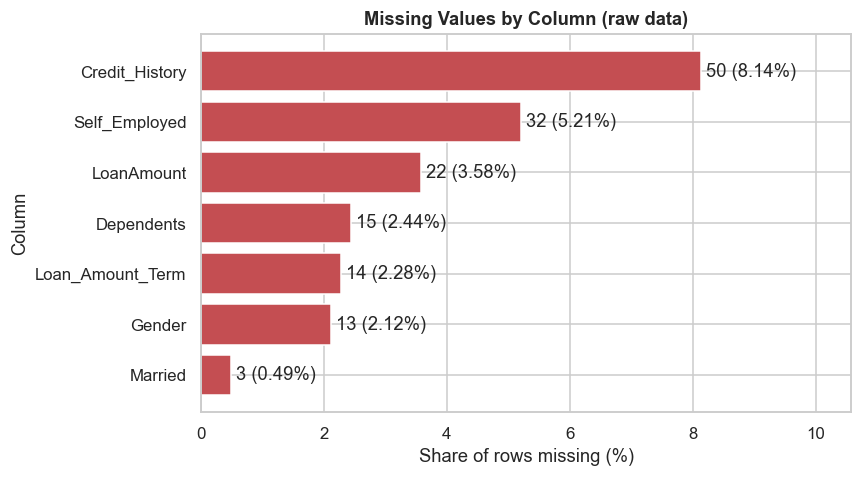

In [7]:
miss_plot = missing[missing["missing_count"] > 0].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(miss_plot.index, miss_plot["missing_pct"], color=sns.color_palette("deep")[3])
ax.bar_label(bars, labels=[f"{n} ({p}%)" for n, p in zip(miss_plot["missing_count"], miss_plot["missing_pct"])], padding=3)
ax.set_title("Missing Values by Column (raw data)")
ax.set_xlabel("Share of rows missing (%)")
ax.set_ylabel("Column")
ax.set_xlim(0, miss_plot["missing_pct"].max() * 1.3)
save_fig("01_missing_values")

**Visualization 2 – Target distribution.** The classes are imbalanced (more approvals than rejections). A model that always predicts "approved" would already look decent on accuracy, so later we judge models with F1 and ROC-AUC as well, not accuracy alone.

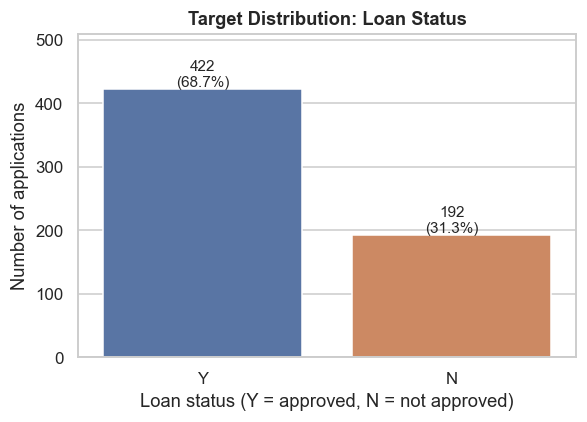

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4))
order = ["Y", "N"]
sns.countplot(data=df_raw, x="Loan_Status", order=order, hue="Loan_Status", hue_order=order, legend=False, ax=ax)
total = len(df_raw)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/total:.1%})", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Target Distribution: Loan Status")
ax.set_xlabel("Loan status (Y = approved, N = not approved)")
ax.set_ylabel("Number of applications")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
save_fig("02_target_distribution")

## 4. Data Cleaning  *(Assignment Part 3: Data Cleaning)*

| Decision | Reason |
|---|---|
| Trim whitespace in text columns | Prevents `"Male "` and `"Male"` being treated as different categories |
| Rename columns to `snake_case` | Clear, consistent, code-friendly names |
| Remove duplicate records | Duplicates would over-weight some applicants (checked ignoring the ID) |
| Drop `loan_id` | A unique identifier carries no predictive signal and could cause overfitting |
| Convert `Dependents` `"3+"` to `3` | Turns a text column into a valid ordinal number |
| Flag missing `Credit_History` before imputing | Missingness itself may be informative (applicants with no credit record) |
| Categorical gaps: **mode** | The most frequent category is the least distorting fill for text categories |
| `Credit_History`, `Loan_Amount_Term`: **mode** | Both are discrete (0/1 flag; fixed terms such as 360 months), so a median or mean would create invalid values |
| `LoanAmount`: **median** | Right-skewed, so the median is robust to large loans; the mean would be pulled upward |

In [9]:
df = df_raw.copy()

# 4.1 Trim whitespace in all text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

# 4.2 Rename columns for clarity
rename_map = {
    "Loan_ID": "loan_id", "Gender": "gender", "Married": "married", "Dependents": "dependents",
    "Education": "education", "Self_Employed": "self_employed",
    "ApplicantIncome": "applicant_income", "CoapplicantIncome": "coapplicant_income",
    "LoanAmount": "loan_amount",            # in thousands
    "Loan_Amount_Term": "loan_term_months", # repayment period in months
    "Credit_History": "credit_history", "Property_Area": "property_area", "Loan_Status": "loan_status",
}
df = df.rename(columns=rename_map)

# 4.3 Remove duplicate records (ignoring the unique ID)
subset = [c for c in df.columns if c != "loan_id"]
n_dups = int(df.duplicated(subset=subset).sum())
df = df.drop_duplicates(subset=subset).reset_index(drop=True)
print(f"Duplicate records removed: {n_dups}")

# 4.4 Drop the identifier column
df = df.drop(columns="loan_id")

# 4.5 Fix 'Dependents' ("3+" -> "3")
df["dependents"] = df["dependents"].replace({"3+": "3"})

# 4.6 Flag missing credit history BEFORE imputing it
df["credit_history_missing"] = df["credit_history"].isna().astype(int)

# 4.7 Impute missing values
for col in ["gender", "married", "dependents", "self_employed"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df["credit_history"] = df["credit_history"].fillna(df["credit_history"].mode()[0])
df["loan_term_months"] = df["loan_term_months"].fillna(df["loan_term_months"].mode()[0])
df["loan_amount"] = df["loan_amount"].fillna(df["loan_amount"].median())

# 4.8 Correct data types
df["dependents"] = df["dependents"].astype(int)
df["credit_history"] = df["credit_history"].astype(int)
df["loan_term_months"] = df["loan_term_months"].astype(int)

# 4.9 Verify
print(f"Missing values remaining: {int(df.isna().sum().sum())}")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
df.head()

Duplicate records removed: 0
Missing values remaining: 0


,dtype,missing
gender,object,0
married,object,0
dependents,int32,0
education,object,0
self_employed,object,0
applicant_income,int64,0
coapplicant_income,float64,0
loan_amount,float64,0
loan_term_months,int32,0
credit_history,int32,0


,gender,married,dependents,education,self_employed,applicant_income,coapplicant_income,loan_amount,loan_term_months,credit_history,property_area,loan_status,credit_history_missing
0,Male,No,0,Graduate,No,5849,0.0,128.0,360,1,Urban,Y,0
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360,1,Rural,N,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360,1,Urban,Y,0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360,1,Urban,Y,0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360,1,Urban,Y,0


In [10]:
# Save the cleaned (still human-readable, un-encoded) dataset
df.to_csv("data/processed/cleaned_loan_data.csv", index=False)
print("Saved: data/processed/cleaned_loan_data.csv", df.shape)

Saved: data/processed/cleaned_loan_data.csv (614, 13)


> **Note on leakage.** Imputation values (mode / median) are computed on the full dataset here so the assignment deliverable is a single ready-to-use file. When you build the model later, compute imputers and scalers on the training split only (for example with a scikit-learn `Pipeline`).

## 5. Exploratory Visuals: key relationships

These plots guide the feature engineering and outlier decisions that follow.

**Visualization 3 – Income and loan amount distributions.** Both are strongly right-skewed with a long tail of very large values, which is a signal to apply a log transform.

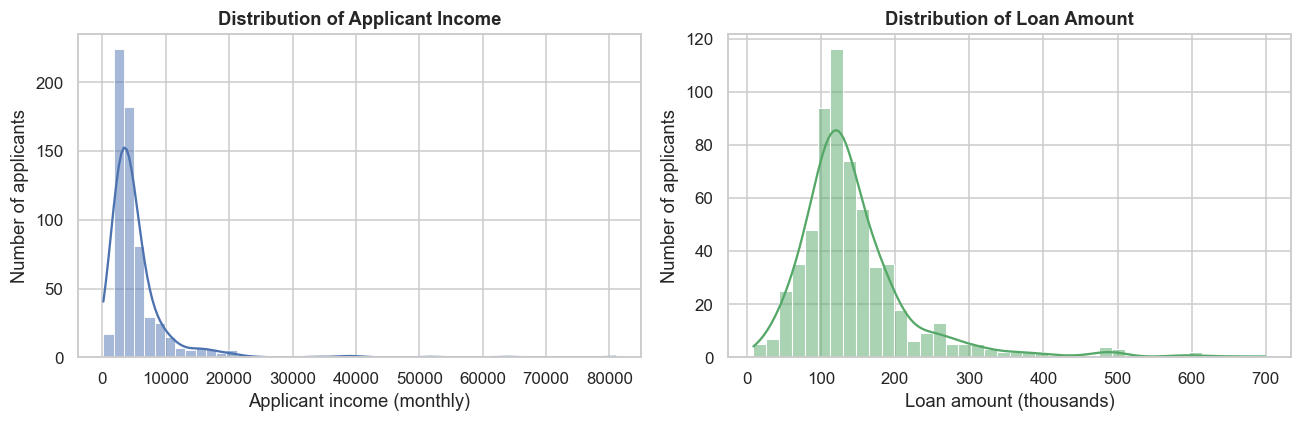

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["applicant_income"], bins=50, kde=True, ax=axes[0], color=sns.color_palette("deep")[0])
axes[0].set_title("Distribution of Applicant Income")
axes[0].set_xlabel("Applicant income (monthly)")
axes[0].set_ylabel("Number of applicants")
sns.histplot(df["loan_amount"], bins=40, kde=True, ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].set_title("Distribution of Loan Amount")
axes[1].set_xlabel("Loan amount (thousands)")
axes[1].set_ylabel("Number of applicants")
save_fig("03_income_loan_distributions")

**Visualization 4 – Approval by credit history and property area.** Applicants whose credit history meets guidelines (1) are approved far more often, while almost everyone with a credit history of 0 is rejected. Property area matters less, though Semiurban applications show the highest approval share.

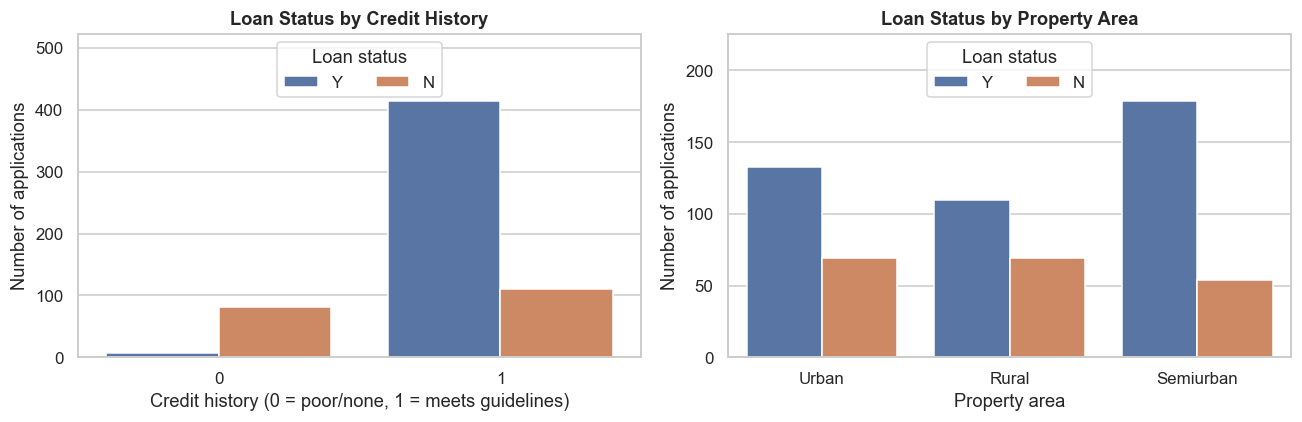

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="credit_history", hue="loan_status", hue_order=["Y", "N"], ax=axes[0])
axes[0].set_title("Loan Status by Credit History")
axes[0].set_xlabel("Credit history (0 = poor/none, 1 = meets guidelines)")
axes[0].set_ylabel("Number of applications")
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.2)
axes[0].legend(title="Loan status", ncol=2, loc="upper center")
sns.countplot(data=df, x="property_area", hue="loan_status", hue_order=["Y", "N"], ax=axes[1])
axes[1].set_title("Loan Status by Property Area")
axes[1].set_xlabel("Property area")
axes[1].set_ylabel("Number of applications")
axes[1].set_ylim(0, axes[1].get_ylim()[1] * 1.2)
axes[1].legend(title="Loan status", ncol=2, loc="upper center")
save_fig("04_status_by_credit_and_area")

**Visualization 5 – Applicant income vs loan amount.** Larger incomes tend to go with larger loans, but most applicants sit in a dense cluster at the bottom-left, a handful of very high incomes stretch the axes, and high income alone does not guarantee approval.

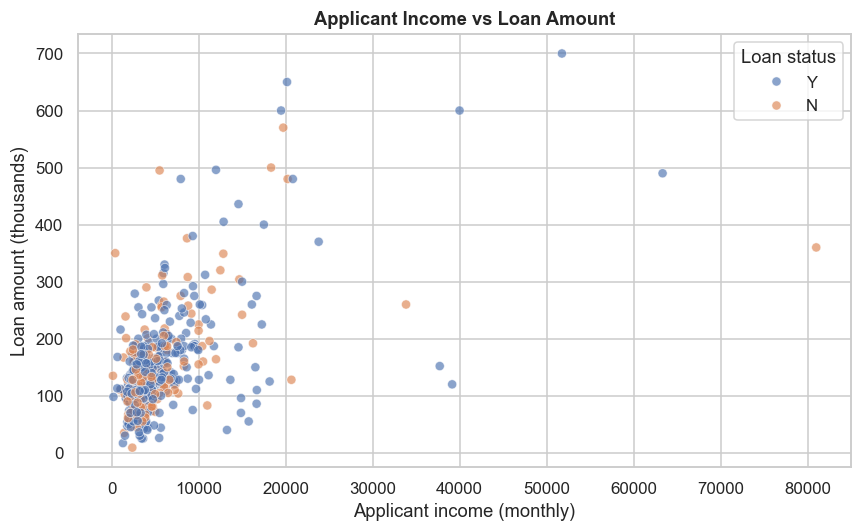

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="applicant_income", y="loan_amount", hue="loan_status", hue_order=["Y", "N"],
                alpha=0.65, ax=ax)
ax.set_title("Applicant Income vs Loan Amount")
ax.set_xlabel("Applicant income (monthly)")
ax.set_ylabel("Loan amount (thousands)")
ax.legend(title="Loan status")
save_fig("05_income_vs_loan_scatter")

## 6. Feature Engineering  *(Assignment Part 3: Feature Engineering)*

New features turn raw columns into quantities that reflect how lenders actually judge affordability.

| New feature | Formula | Why it helps |
|---|---|---|
| `total_income` | applicant + coapplicant income | Repayment capacity depends on the household, not one person |
| `has_coapplicant` | coapplicant income > 0 | Simple flag for dual-income applications |
| `emi` | loan amount × 1000 ÷ term (months) | Approximate monthly repayment (interest ignored, so it is a proxy) |
| `emi_to_income` | emi ÷ total income | Repayment burden: share of monthly income going to the loan |
| `balance_income` | total income − emi | Income left after the repayment |

`loan_id` was already removed as irrelevant (Section 4). Columns were renamed in Section 4.

In [14]:
fe = df.copy()

fe["total_income"] = fe["applicant_income"] + fe["coapplicant_income"]
fe["has_coapplicant"] = (fe["coapplicant_income"] > 0).astype(int)
fe["emi"] = fe["loan_amount"] * 1000 / fe["loan_term_months"]   # loan_amount is in thousands
fe["emi_to_income"] = fe["emi"] / fe["total_income"]
fe["balance_income"] = fe["total_income"] - fe["emi"]

display(fe[["applicant_income", "coapplicant_income", "total_income", "has_coapplicant",
            "loan_amount", "emi", "emi_to_income", "balance_income"]].head(10))
print("New features:", ["total_income", "has_coapplicant", "emi", "emi_to_income", "balance_income"])

,applicant_income,coapplicant_income,total_income,has_coapplicant,loan_amount,emi,emi_to_income,balance_income
0,5849,0.0,5849.0,0,128.0,355.555556,0.060789,5493.444444
1,4583,1508.0,6091.0,1,128.0,355.555556,0.058374,5735.444444
2,3000,0.0,3000.0,0,66.0,183.333333,0.061111,2816.666667
3,2583,2358.0,4941.0,1,120.0,333.333333,0.067463,4607.666667
4,6000,0.0,6000.0,0,141.0,391.666667,0.065278,5608.333333
5,5417,4196.0,9613.0,1,267.0,741.666667,0.077152,8871.333333
6,2333,1516.0,3849.0,1,95.0,263.888889,0.068560,3585.111111
7,3036,2504.0,5540.0,1,158.0,438.888889,0.079222,5101.111111
8,4006,1526.0,5532.0,1,168.0,466.666667,0.084358,5065.333333
9,12841,10968.0,23809.0,1,349.0,969.444444,0.040718,22839.555556


New features: ['total_income', 'has_coapplicant', 'emi', 'emi_to_income', 'balance_income']


## 7. Outlier Detection & Treatment  *(Assignment Part 3: Outlier Detection)*

**Detection.** Two complementary methods are used on every continuous column:
- **IQR method:** a value is an outlier if it lies outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. It makes no normality assumption, so it suits skewed money columns.
- **Z-score:** a value is an outlier if `|z| > 3`. It assumes a roughly symmetric distribution, so on skewed data it is used only as a cross-check.

**Treatment.** The dataset is small (about 600 rows) and extreme incomes and loans are *real* applicants, so **rows are not deleted**. Instead:
1. **Log-transform** skewed money columns (`log1p`) to compress the long tail.
2. **Winsorize (cap)** what remains at the IQR fences so a few points cannot dominate the model.
3. `loan_term_months` is left alone: 360 months dominates, so the IQR collapses and every other tenor looks like an "outlier", yet they are valid loan terms.

In [15]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def outlier_table(frame, cols):
    rows = []
    for c in cols:
        s = frame[c]
        lo, hi = iqr_bounds(s)
        rows.append({
            "feature": c,
            "IQR_outliers": int(((s < lo) | (s > hi)).sum()),
            "zscore_outliers(|z|>3)": int((np.abs(stats.zscore(s)) > 3).sum()),
            "skewness": round(s.skew(), 2),
        })
    return pd.DataFrame(rows).set_index("feature")

detect_cols = ["applicant_income", "coapplicant_income", "loan_amount", "total_income",
               "emi", "emi_to_income", "balance_income", "loan_term_months"]
outliers_before = outlier_table(fe, detect_cols)
print("Outliers BEFORE treatment")
display(outliers_before)

Outliers BEFORE treatment


,IQR_outliers,zscore_outliers(|z|>3),skewness
feature,,,
applicant_income,50,8,6.54
coapplicant_income,18,6,7.49
loan_amount,41,15,2.74
total_income,50,10,5.63
emi,50,9,9.96
emi_to_income,51,4,11.26
balance_income,52,10,5.71
loan_term_months,88,12,-2.40


**Visualization 6 – Box plots before treatment.** Points beyond the whiskers are the IQR outliers.

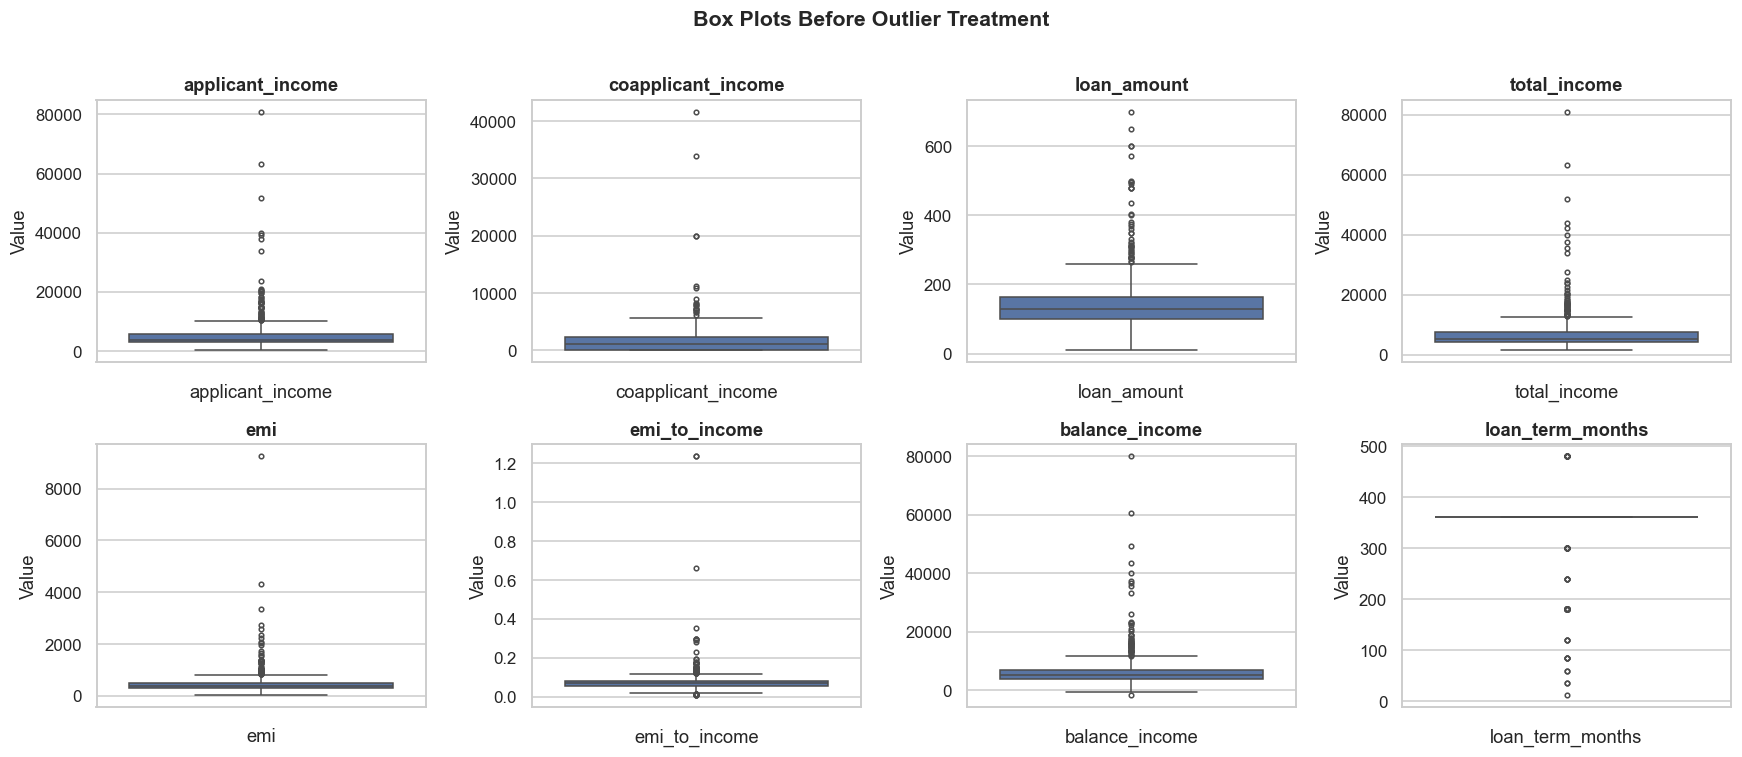

In [16]:
def boxplot_grid(frame, cols, title, fname, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        sns.boxplot(y=frame[c], ax=ax, color=sns.color_palette("deep")[0], flierprops={"markersize": 3})
        ax.set_title(c)
        ax.set_ylabel("Value")
        ax.set_xlabel(c)
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.01)
    save_fig(fname)

boxplot_grid(fe, detect_cols, "Box Plots Before Outlier Treatment", "06_boxplots_before")

### 7.1 Apply treatment: log transform, then cap at the IQR fences

In [17]:
# 1) Log-transform skewed money columns (log1p handles zeros safely)
fe["log_total_income"]   = np.log1p(fe["total_income"])
fe["log_loan_amount"]    = np.log1p(fe["loan_amount"])
fe["log_emi"]            = np.log1p(fe["emi"])
fe["log_balance_income"] = np.log1p(fe["balance_income"].clip(lower=0))

# 2) Winsorize the transformed columns (and the repayment ratio) at the IQR fences
cap_cols = ["log_total_income", "log_loan_amount", "log_emi", "log_balance_income", "emi_to_income"]
for c in cap_cols:
    lo, hi = iqr_bounds(fe[c])
    fe[c] = fe[c].clip(lower=lo, upper=hi)

print("Rows kept:", len(fe), "(no rows were deleted)\n")
print("Outliers AFTER treatment (transformed / capped columns)")
display(outlier_table(fe, cap_cols))

print("Skewness before vs after the log transform")
display(pd.DataFrame({
    "before": [fe[c].skew() for c in ["total_income", "loan_amount", "emi", "balance_income"]],
    "after":  [fe[c].skew() for c in ["log_total_income", "log_loan_amount", "log_emi", "log_balance_income"]],
}, index=["total_income", "loan_amount", "emi", "balance_income"]).round(2))

Rows kept: 614 (no rows were deleted)

Outliers AFTER treatment (transformed / capped columns)


,IQR_outliers,zscore_outliers(|z|>3),skewness
feature,,,
log_total_income,0,0,0.48
log_loan_amount,0,0,0.04
log_emi,0,0,0.28
log_balance_income,0,0,0.40
emi_to_income,0,0,0.26


Skewness before vs after the log transform


,before,after
total_income,5.63,0.48
loan_amount,2.74,0.04
emi,9.96,0.28
balance_income,5.71,0.40


**Visualization 7 – Box plots after treatment.** The long tails are gone: whiskers now cover almost all of the data.

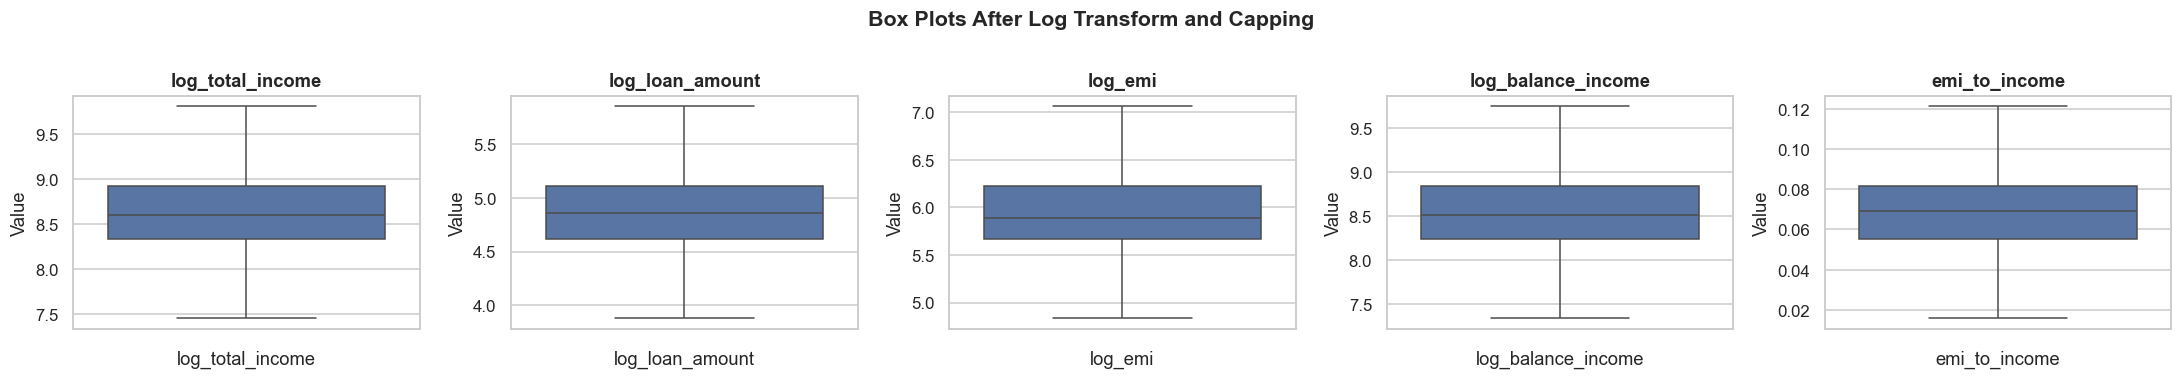

In [18]:
boxplot_grid(fe, cap_cols, "Box Plots After Log Transform and Capping", "07_boxplots_after", ncols=5)

## 8. Feature Encoding  *(Assignment Part 3: Feature Encoding)*

| Column(s) | Technique | Why |
|---|---|---|
| `gender`, `married`, `education`, `self_employed` | **Label Encoding** | Each has exactly two categories, so a single 0/1 column loses no information and adds no extra columns |
| `loan_status` (target) | **Label Encoding** | Targets are label-encoded: N = 0, Y = 1 |
| `property_area` (Rural / Semiurban / Urban) | **One-Hot Encoding** (`drop_first=True`) | Three categories with **no natural order**. Label encoding would imply Urban > Semiurban > Rural. Dropping one dummy avoids perfect multicollinearity (the dummy variable trap) |
| `dependents`, `credit_history`, `loan_term_months` | *Already numeric* | `dependents` is a true ordinal count (0–3); `credit_history` is already a 0/1 flag |

In [19]:
enc = fe.copy()

# Label-encode binary columns and print the mapping so it is documented
binary_cols = ["gender", "married", "education", "self_employed"]
for col in binary_cols:
    le = LabelEncoder()
    enc[col] = le.fit_transform(enc[col])
    print(f"{col:14s} ->", {k: int(v) for k, v in zip(le.classes_, le.transform(le.classes_))})

# Label-encode the target
le_target = LabelEncoder()
enc["loan_status"] = le_target.fit_transform(enc["loan_status"])
print(f"{'loan_status':14s} ->", {k: int(v) for k, v in zip(le_target.classes_, le_target.transform(le_target.classes_))})

# One-hot encode the nominal column
enc = pd.get_dummies(enc, columns=["property_area"], drop_first=True, dtype=int)
print("\nOne-hot columns created:", [c for c in enc.columns if c.startswith("property_area_")])
print("Encoded dataset shape:", enc.shape)
enc.head()

gender         -> {'Female': 0, 'Male': 1}
married        -> {'No': 0, 'Yes': 1}
education      -> {'Graduate': 0, 'Not Graduate': 1}
self_employed  -> {'No': 0, 'Yes': 1}
loan_status    -> {'N': 0, 'Y': 1}

One-hot columns created: ['property_area_Semiurban', 'property_area_Urban']
Encoded dataset shape: (614, 23)


,gender,married,dependents,education,self_employed,applicant_income,coapplicant_income,loan_amount,loan_term_months,credit_history,...,has_coapplicant,emi,emi_to_income,balance_income,log_total_income,log_loan_amount,log_emi,log_balance_income,property_area_Semiurban,property_area_Urban
0,1,0,0,0,0,5849,0.0,128.0,360,1,...,0,355.555556,0.060789,5493.444444,8.674197,4.859812,5.876490,8.611493,0,1
1,1,1,1,0,0,4583,1508.0,128.0,360,1,...,1,355.555556,0.058374,5735.444444,8.714732,4.859812,5.876490,8.654595,0,0
2,1,1,0,0,1,3000,0.0,66.0,360,1,...,0,183.333333,0.061111,2816.666667,8.006701,4.204693,5.216746,7.943664,0,1
3,1,1,0,1,0,2583,2358.0,120.0,360,1,...,1,333.333333,0.067463,4607.666667,8.505525,4.795791,5.812138,8.435694,0,1
4,1,0,0,0,0,6000,0.0,141.0,360,1,...,0,391.666667,0.065278,5608.333333,8.699681,4.955827,5.972961,8.632187,0,1


## 9. Feature Scaling  *(Assignment Part 3: Feature Scaling)*

**Which columns?** Only the continuous model features: the four log-money columns, `emi_to_income` and `loan_term_months`. Binary 0/1 columns and one-hot dummies are not scaled because they are already on a 0–1 scale.

**Why `RobustScaler`?** It centres on the **median** and scales by the **IQR**, so any leftover extreme values barely affect it. `StandardScaler` uses the mean and standard deviation, and `MinMaxScaler` uses the min and max, and both are pulled by outliers. For `loan_term_months`, whose IQR is zero because most values are 360, scikit-learn leaves the scale at 1, so the column is simply centred.

Scaling matters for distance-based and gradient-based models (logistic regression, SVM, KNN, neural nets). Tree-based models do not need it, but scaling does no harm.

In [20]:
scale_cols = ["log_total_income", "log_loan_amount", "log_emi", "log_balance_income",
              "emi_to_income", "loan_term_months"]

scaler = RobustScaler()
scaled = enc.copy()
scaled[scale_cols] = scaler.fit_transform(enc[scale_cols])

summary = pd.DataFrame({
    "median_before": enc[scale_cols].median(), "IQR_before": enc[scale_cols].quantile(.75) - enc[scale_cols].quantile(.25),
    "median_after": scaled[scale_cols].median(), "IQR_after": scaled[scale_cols].quantile(.75) - scaled[scale_cols].quantile(.25),
}).round(3)
display(summary)

,median_before,IQR_before,median_after,IQR_after
log_total_income,8.597,0.591,0.0,1.0
log_loan_amount,4.860,0.493,0.0,1.0
log_emi,5.892,0.558,0.0,1.0
log_balance_income,8.513,0.604,0.0,1.0
emi_to_income,0.069,0.026,0.0,1.0
loan_term_months,360.000,0.000,0.0,0.0


**Visualization 8 – Distributions before and after scaling.** The shape is preserved; only the location and spread change.

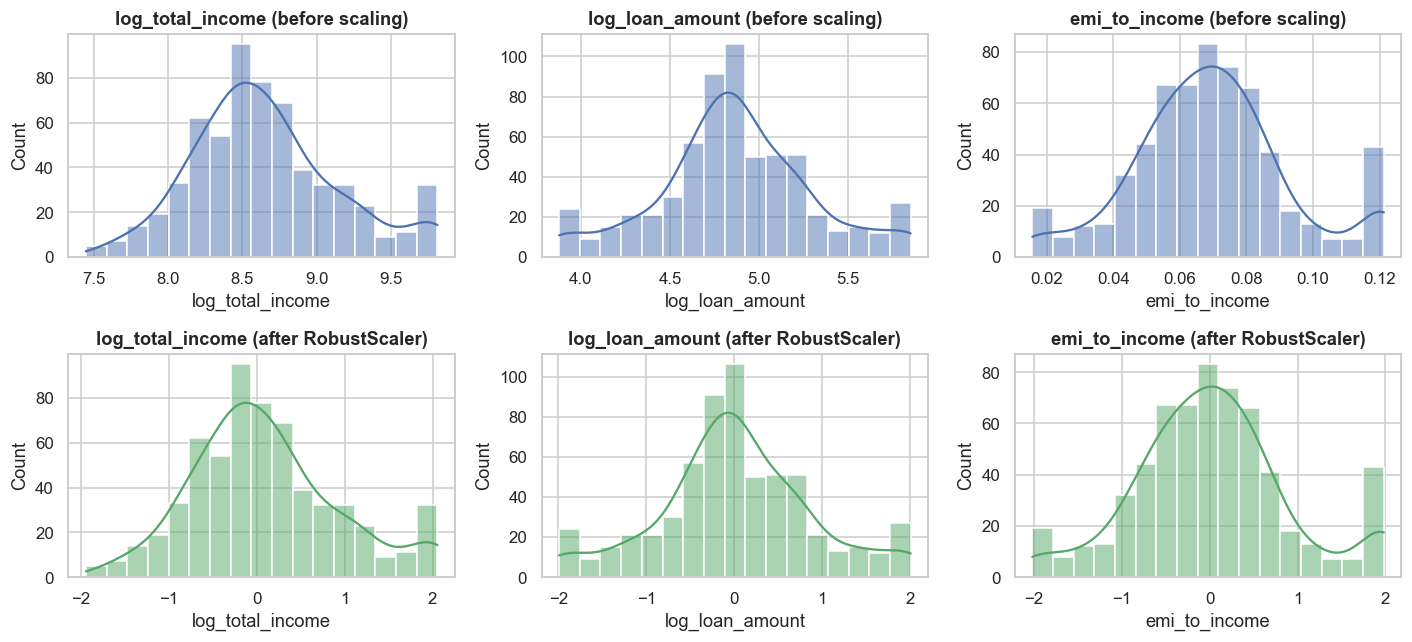

In [21]:
show = ["log_total_income", "log_loan_amount", "emi_to_income"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(show):
    sns.histplot(enc[c], kde=True, ax=axes[0, j], color=sns.color_palette("deep")[0])
    axes[0, j].set_title(f"{c} (before scaling)")
    axes[0, j].set_xlabel(c)
    axes[0, j].set_ylabel("Count")
    sns.histplot(scaled[c], kde=True, ax=axes[1, j], color=sns.color_palette("deep")[2])
    axes[1, j].set_title(f"{c} (after RobustScaler)")
    axes[1, j].set_xlabel(c)
    axes[1, j].set_ylabel("Count")
save_fig("08_scaling_before_after")

## 10. Feature Selection  *(Assignment Part 4)*

The selection process has three documented steps:

1. **Remove superseded raw columns.** The raw money columns (`applicant_income`, `coapplicant_income`, `loan_amount`, `total_income`, `emi`, `balance_income`) are replaced by their transformed, outlier-treated versions, and keeping both would duplicate information.
2. **Remove highly correlated features.** For any pair with |r| > 0.8, keep the feature with the higher Random Forest importance.
3. **Remove clearly uninformative features.** (One-hot dummies of the same variable are kept or dropped together.) A feature is dropped only if its Random Forest importance is below half the average **and** its permutation importance on held-out data is not positive. Requiring both guards against Random Forest's bias toward continuous columns.

> **Fairness note.** `gender` and `married` are sensitive attributes. Even if they are statistically useful, a real lender may be legally or ethically barred from using them in credit decisions. Their importance is reported openly here, and a production model should be reviewed for fairness before deployment.

**Visualization 9 – Correlation heatmap** of all encoded features, including the raw columns, so redundancy is visible.

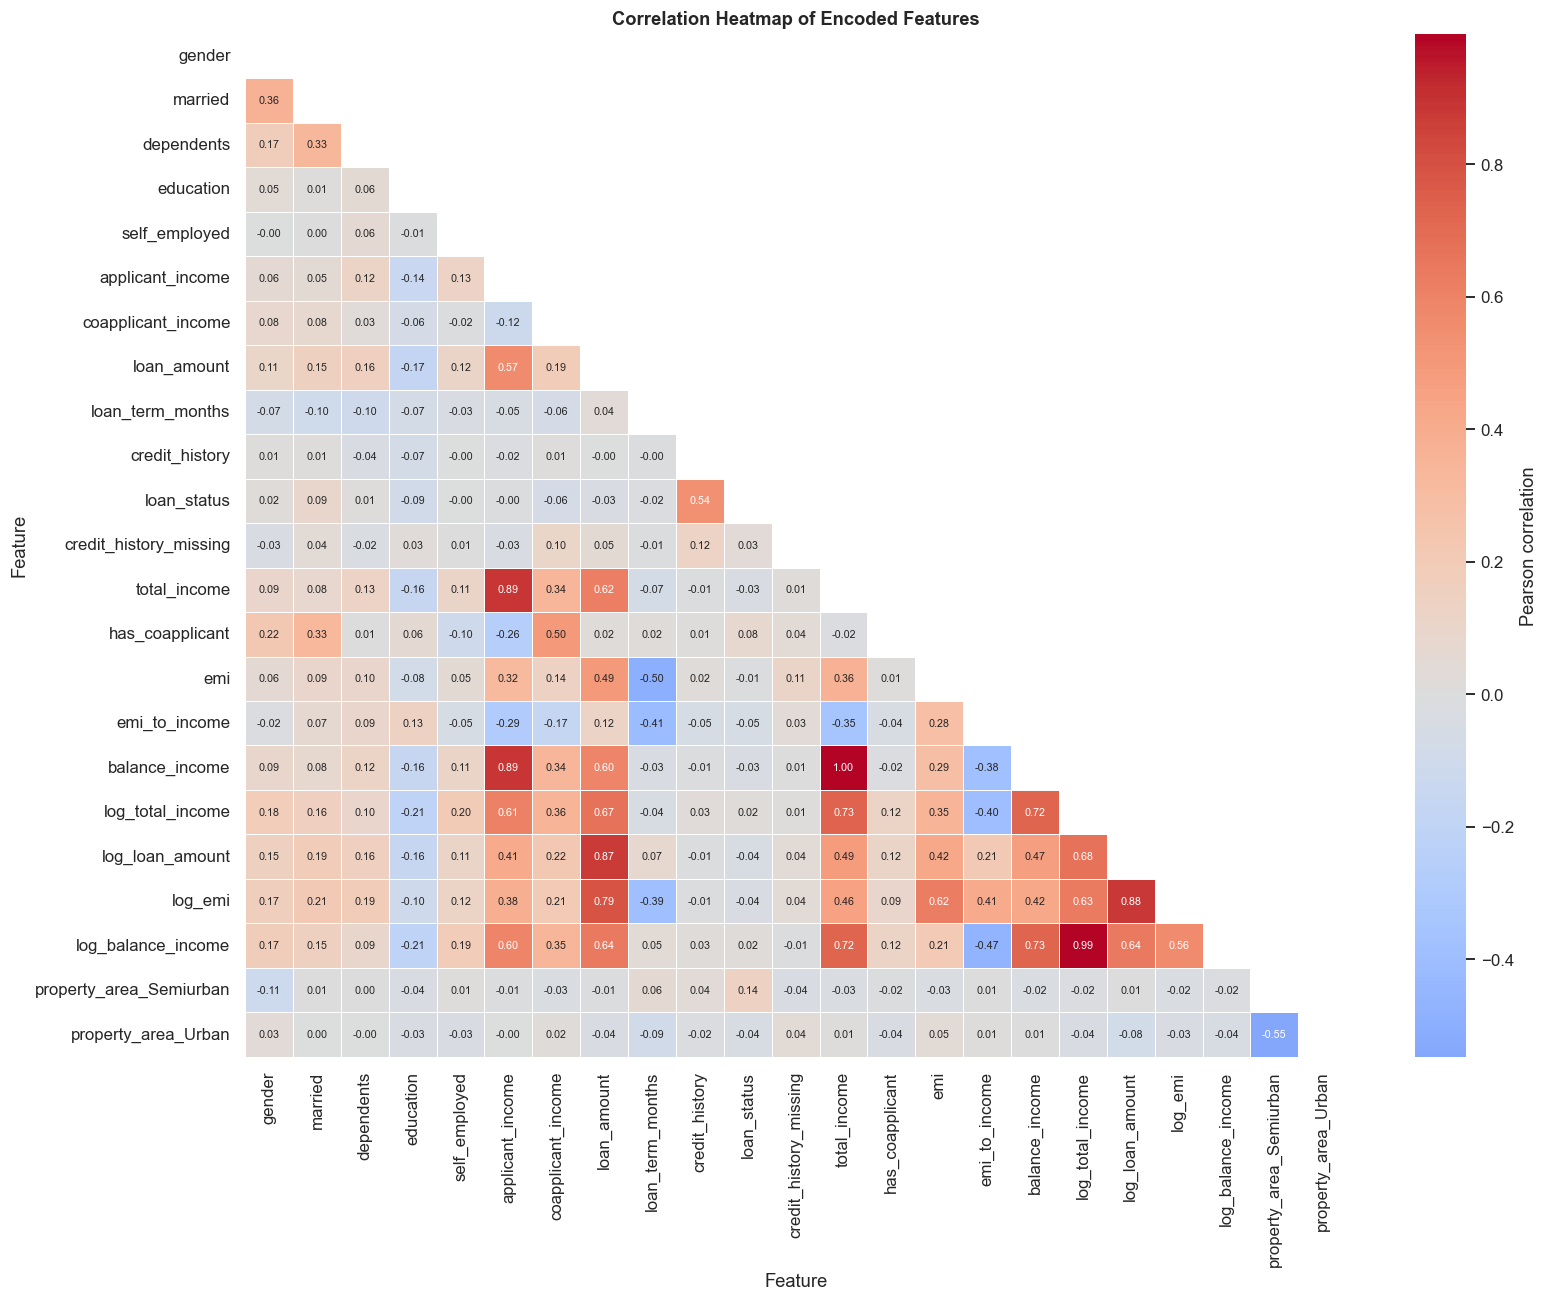

Highly correlated pairs (|r| > 0.8):


correlation
total_income     balance_income            0.997
log_total_income log_balance_income        0.987
applicant_income total_income              0.893
                 balance_income            0.891
log_loan_amount  log_emi                   0.880
loan_amount      log_loan_amount           0.873

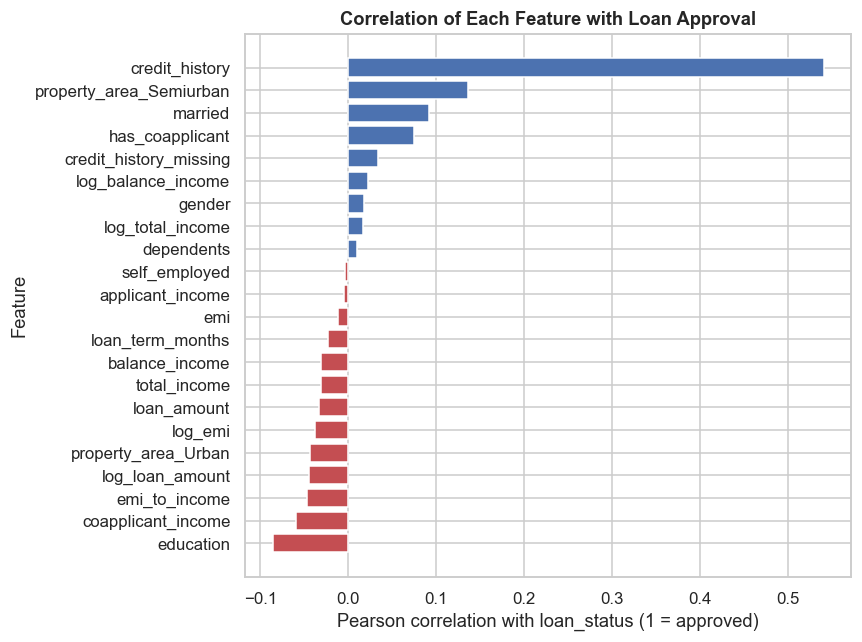

In [22]:
sel = scaled.copy()
corr = sel.corr()

fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Encoded Features")
ax.grid(False)
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
save_fig("09_correlation_heatmap")

# Highly correlated pairs (|r| > 0.8)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
print("Highly correlated pairs (|r| > 0.8):")
display(high_pairs.round(3).rename("correlation").to_frame())

# Correlation of every feature with the target
target_corr = corr["loan_status"].drop("loan_status").sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(target_corr.index, target_corr.values,
        color=["#c44e52" if v < 0 else "#4c72b0" for v in target_corr.values])
ax.set_title("Correlation of Each Feature with Loan Approval")
ax.set_xlabel("Pearson correlation with loan_status (1 = approved)")
ax.set_ylabel("Feature")
save_fig("10_target_correlation")

### 10.1 Random Forest and permutation importance

In [23]:
RAW_SUPERSEDED = ["applicant_income", "coapplicant_income", "loan_amount", "total_income", "emi", "balance_income"]
candidates = [c for c in sel.columns if c not in RAW_SUPERSEDED + ["loan_status"]]

X, y = sel[candidates], sel["loan_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

imp_rf = pd.Series(rf.feature_importances_, index=candidates)
perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc")
imp_perm = pd.Series(perm.importances_mean, index=candidates)

importance = pd.DataFrame({"rf_importance": imp_rf, "permutation_importance": imp_perm}).sort_values("rf_importance", ascending=False)
display(importance.round(4))

,rf_importance,permutation_importance
credit_history,0.2644,0.2906
emi_to_income,0.1252,0.0211
log_total_income,0.1109,0.0147
log_balance_income,0.1076,0.0115
log_loan_amount,0.1053,0.0095
log_emi,0.1031,-0.0036
dependents,0.0338,-0.0009
property_area_Semiurban,0.0310,0.0137
has_coapplicant,0.0270,0.0010
married,0.0204,0.0010


**Visualization 10 – Feature importance** from two independent methods.

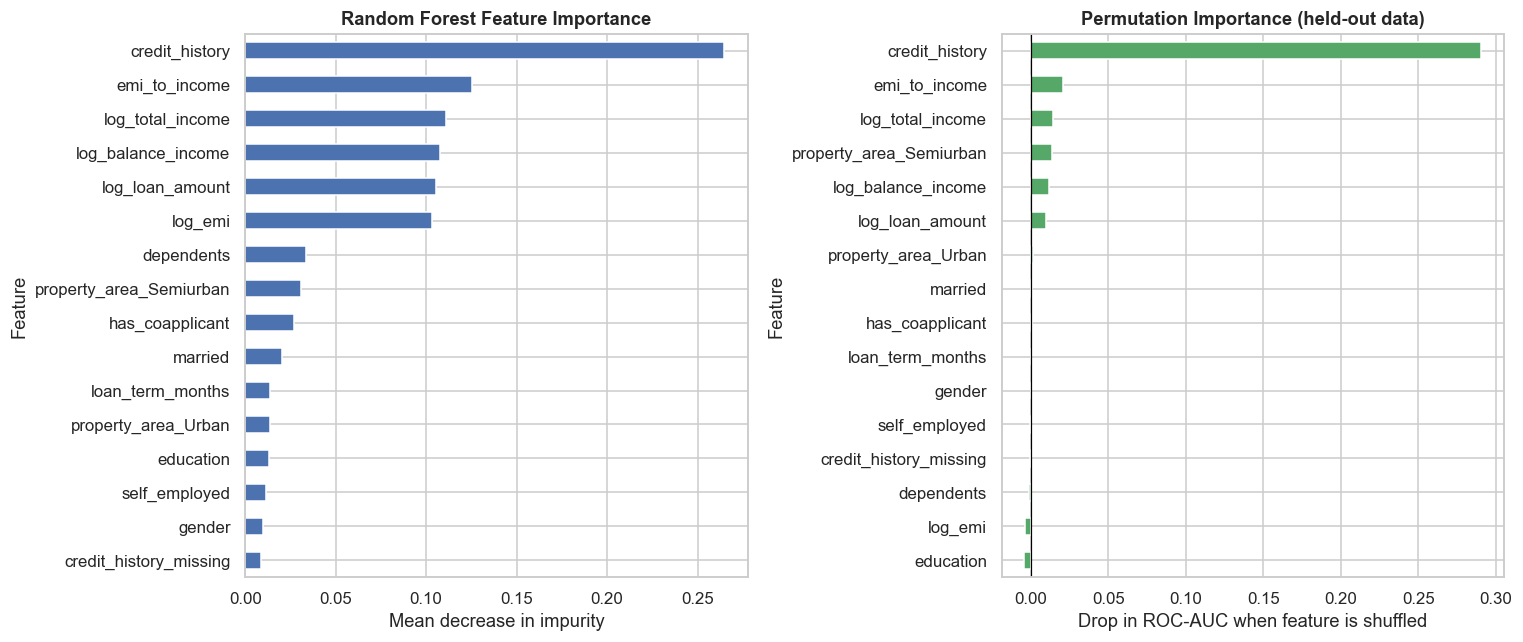

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp_rf.sort_values().plot.barh(ax=axes[0], color=sns.color_palette("deep")[0])
axes[0].set_title("Random Forest Feature Importance")
axes[0].set_xlabel("Mean decrease in impurity")
axes[0].set_ylabel("Feature")
imp_perm.sort_values().plot.barh(ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].set_title("Permutation Importance (held-out data)")
axes[1].set_xlabel("Drop in ROC-AUC when feature is shuffled")
axes[1].set_ylabel("Feature")
axes[1].axvline(0, color="black", lw=0.8)
save_fig("11_feature_importance")

### 10.2 Apply the selection rules

In [25]:
dropped = {}   # feature -> reason

# Step 1: raw columns superseded by transformed versions
for c in RAW_SUPERSEDED:
    dropped[c] = "superseded by log-transformed / treated version"

# Step 2: highly correlated pairs among the remaining candidates (keep the more important one)
cand_corr = sel[candidates].corr().abs()
for i, a in enumerate(candidates):
    for b in candidates[i + 1:]:
        if a in dropped or b in dropped:
            continue
        if cand_corr.loc[a, b] > 0.8:
            loser = a if imp_rf[a] < imp_rf[b] else b
            winner = b if loser == a else a
            dropped[loser] = f"|r|={cand_corr.loc[a, b]:.2f} with {winner} (lower importance)"

# Step 3: clearly uninformative features
threshold = 0.5 * imp_rf.mean()
def is_uninformative(c):
    return imp_rf[c] < threshold and imp_perm[c] <= 0

# One-hot dummies of the same variable are kept or dropped TOGETHER (dropping one would break the encoding)
area_cols = [c for c in candidates if c.startswith("property_area_") and c not in dropped]
if area_cols and all(is_uninformative(c) for c in area_cols):
    for c in area_cols:
        dropped[c] = "all property_area dummies have low importance"

for c in candidates:
    if c in dropped or c in area_cols:
        continue
    if is_uninformative(c):
        dropped[c] = f"low importance (RF {imp_rf[c]:.3f} < {threshold:.3f}) and permutation importance <= 0"

final_features = [c for c in candidates if c not in dropped]

print("DROPPED FEATURES")
display(pd.Series(dropped, name="reason").to_frame())
print("\nSELECTED FEATURES (%d):" % len(final_features))
for c in final_features:
    print(f"  - {c}")

DROPPED FEATURES


,reason
applicant_income,superseded by log-transformed / treated version
coapplicant_income,superseded by log-transformed / treated version
loan_amount,superseded by log-transformed / treated version
total_income,superseded by log-transformed / treated version
emi,superseded by log-transformed / treated version
balance_income,superseded by log-transformed / treated version
log_balance_income,|r|=0.99 with log_total_income (lower importance)
log_emi,|r|=0.88 with log_loan_amount (lower importance)
gender,low importance (RF 0.010 < 0.031) and permutat...
education,low importance (RF 0.013 < 0.031) and permutat...



SELECTED FEATURES (10):
  - married
  - dependents
  - loan_term_months
  - credit_history
  - has_coapplicant
  - emi_to_income
  - log_total_income
  - log_loan_amount
  - property_area_Semiurban
  - property_area_Urban


**Reading the results.** `credit_history` is by far the most important feature in both methods. The affordability features (`emi_to_income`, `log_total_income`, `log_loan_amount`) come next. `log_balance_income` and `log_emi` were removed as redundant, being highly correlated with `log_total_income` and `log_loan_amount`. `gender`, `education`, `self_employed` and `credit_history_missing` carried almost no extra signal and were removed. `married` was kept because its permutation importance was marginally positive, but it is a sensitive attribute and should be reviewed for fairness before modelling.

## 11. Final Machine-Learning Dataset  *(Assignment Part 5)*

The final dataset contains only the selected features plus the target. It must be fully numeric, free of missing values, and contain no identifiers.

In [26]:
ml_ready = sel[final_features + ["loan_status"]].copy()

# Readiness checks
assert ml_ready.isna().sum().sum() == 0, "Missing values remain"
assert all(pd.api.types.is_numeric_dtype(t) for t in ml_ready.dtypes), "Non-numeric column found"
assert not ml_ready.duplicated().all()

print("Final shape:", ml_ready.shape)
print("Missing values:", int(ml_ready.isna().sum().sum()))
print("Target balance:\n", ml_ready["loan_status"].value_counts(normalize=True).round(3).rename({1: "approved (1)", 0: "not approved (0)"}))

ml_ready.to_csv("data/processed/ml_ready_loan_data.csv", index=False)
print("\nSaved: data/processed/ml_ready_loan_data.csv")
ml_ready.head(10)

Final shape: (614, 11)
Missing values: 0
Target balance:
 loan_status
approved (1)        0.687
not approved (0)    0.313
Name: proportion, dtype: float64

Saved: data/processed/ml_ready_loan_data.csv


,married,dependents,loan_term_months,credit_history,has_coapplicant,emi_to_income,log_total_income,log_loan_amount,property_area_Semiurban,property_area_Urban,loan_status
0,0,0,0.0,1,0,-0.309953,0.130021,0.000000,0,1,1
1,1,1,0.0,1,1,-0.401460,0.198639,0.000000,0,0,0
2,1,0,0.0,1,0,-0.297753,-0.999929,-1.329130,0,1,1
3,1,0,0.0,1,1,-0.057102,-0.155510,-0.129890,0,1,1
4,0,0,0.0,1,0,-0.139886,0.173161,0.194798,0,1,1
5,1,2,0.0,1,1,0.310024,0.970977,1.483433,0,1,1
6,1,0,0.0,1,1,-0.015514,-0.578201,-0.599448,0,1,1
7,1,3,0.0,0,1,0.388428,0.038157,0.424213,1,0,0
8,1,2,0.0,1,1,0.583016,0.035711,0.547961,0,1,1
9,1,1,0.0,1,1,-1.070427,2.055740,2.008558,1,0,0


### 11.1 Data dictionary of the final dataset

In [27]:
descriptions = {
    "gender": "Applicant gender (label encoded, see mapping above)",
    "married": "Married (label encoded: No = 0, Yes = 1)",
    "dependents": "Number of dependents (0-3, where 3 means 3 or more)",
    "education": "Education (label encoded: Graduate = 0, Not Graduate = 1)",
    "self_employed": "Self-employed (label encoded: No = 0, Yes = 1)",
    "loan_term_months": "Loan term in months (robust-scaled)",
    "credit_history": "1 = credit history meets guidelines, 0 = does not",
    "credit_history_missing": "1 = credit history was missing in the raw data",
    "has_coapplicant": "1 = application has a co-applicant with income",
    "emi_to_income": "Approx. monthly repayment / total income (capped, robust-scaled)",
    "log_total_income": "log1p(applicant + coapplicant income), capped, robust-scaled",
    "log_loan_amount": "log1p(loan amount), capped, robust-scaled",
    "log_emi": "log1p(approx. monthly repayment), capped, robust-scaled",
    "log_balance_income": "log1p(income left after repayment), capped, robust-scaled",
    "property_area_Semiurban": "1 = semi-urban property (Rural is the baseline)",
    "property_area_Urban": "1 = urban property (Rural is the baseline)",
    "loan_status": "TARGET: 1 = approved, 0 = not approved",
}
dd = pd.DataFrame({"dtype": ml_ready.dtypes.astype(str)})
dd["description"] = [descriptions.get(c, "") for c in dd.index]
display(dd)

,dtype,description
married,int32,"Married (label encoded: No = 0, Yes = 1)"
dependents,int32,"Number of dependents (0-3, where 3 means 3 or ..."
loan_term_months,float64,Loan term in months (robust-scaled)
credit_history,int32,"1 = credit history meets guidelines, 0 = does not"
has_coapplicant,int32,1 = application has a co-applicant with income
emi_to_income,float64,Approx. monthly repayment / total income (capp...
log_total_income,float64,"log1p(applicant + coapplicant income), capped,..."
log_loan_amount,float64,"log1p(loan amount), capped, robust-scaled"
property_area_Semiurban,int32,1 = semi-urban property (Rural is the baseline)
property_area_Urban,int32,1 = urban property (Rural is the baseline)


### 11.2 Smoke test: is the dataset usable by a model?

This is **not** a model-building exercise (that is next week's task). It only checks that standard estimators can consume the file and learn something beyond the "always approve" baseline.

In [28]:
Xf, yf = ml_ready.drop(columns="loan_status"), ml_ready["loan_status"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics = ["accuracy", "f1", "roc_auc"]

results = {}
for name, model in {
    "Baseline: always approve": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
}.items():
    cvr = cross_validate(model, Xf, yf, cv=cv, scoring=metrics)
    results[name] = {m: cvr[f"test_{m}"].mean() for m in metrics}

smoke = pd.DataFrame(results).T.round(3)
display(smoke)

,accuracy,f1,roc_auc
Baseline: always approve,0.687,0.815,0.500
Logistic Regression,0.762,0.832,0.771
Random Forest,0.800,0.865,0.772


Both models score a ROC-AUC of about 0.77 against 0.50 for the "always approve" baseline, so the prepared features carry real predictive signal. Accuracy gains over the baseline are modest because 69% of applications are approved anyway, which is why F1 and ROC-AUC matter here.

> Scaling and imputation were fitted on the full dataset, so these scores are slightly optimistic. The point of this check is only that the data is model-ready and carries signal.

## 12. Answers to the Business Questions

In [29]:
top3 = importance["rf_importance"].head(3).index.tolist()
enc_vars = binary_cols + ["loan_status (target)", "property_area (one-hot)"]
corr_msg = "none above |r| = 0.8 among the final candidates" if not [k for k, v in dropped.items() if "|r|" in v] else \
           "; ".join(f"{k}: {v}" for k, v in dropped.items() if "|r|" in v)

report = f'''
PREPROCESSING SUMMARY
=====================
Raw data                : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns
Duplicates removed      : {n_dups}
Final ML dataset        : {ml_ready.shape[0]} rows x {ml_ready.shape[1]} columns (incl. target)

Q1. Most relevant features (Random Forest top 3): {", ".join(top3)}
Q2. Variables encoded   : {", ".join(enc_vars)}
Q3. Variables scaled    : {", ".join(scale_cols)} (RobustScaler)
Q4. Redundant / correlated: {len(RAW_SUPERSEDED)} raw money columns superseded by transformed versions;
    correlated pairs (|r|>0.8) dropped: {corr_msg}
Q5. Missing values      : categorical -> mode; credit_history & loan_term -> mode; loan_amount -> median.
    Outliers: log transform + IQR capping, no rows deleted.
Q6. Techniques that improved quality: imputation, type fixes, log transform (skew reduction),
    outlier capping, encoding, robust scaling, redundancy removal.
Q7. Ready for ML?       : Yes. {ml_ready.shape[1]-1} numeric features, 0 missing values, target encoded.
    Smoke-test ROC-AUC (Logistic Regression, 5-fold CV): {smoke.loc["Logistic Regression", "roc_auc"]}
    vs baseline {smoke.loc["Baseline: always approve", "roc_auc"]}.
Dropped features        : {", ".join(dropped)}
Selected features       : {", ".join(final_features)}
'''
print(report)
with open("data/processed/preprocessing_summary.txt", "w") as f:
    f.write(report)


PREPROCESSING SUMMARY
Raw data                : 614 rows x 13 columns
Duplicates removed      : 0
Final ML dataset        : 614 rows x 11 columns (incl. target)

Q1. Most relevant features (Random Forest top 3): credit_history, emi_to_income, log_total_income
Q2. Variables encoded   : gender, married, education, self_employed, loan_status (target), property_area (one-hot)
Q3. Variables scaled    : log_total_income, log_loan_amount, log_emi, log_balance_income, emi_to_income, loan_term_months (RobustScaler)
Q4. Redundant / correlated: 6 raw money columns superseded by transformed versions;
    correlated pairs (|r|>0.8) dropped: log_balance_income: |r|=0.99 with log_total_income (lower importance); log_emi: |r|=0.88 with log_loan_amount (lower importance)
Q5. Missing values      : categorical -> mode; credit_history & loan_term -> mode; loan_amount -> median.
    Outliers: log transform + IQR capping, no rows deleted.
Q6. Techniques that improved quality: imputation, type fixes, log tr

### Conclusion

The raw loan data has been cleaned, enriched with affordability features, transformed to tame skew and outliers, encoded, scaled and reduced to a compact, informative feature set. The resulting file `data/processed/ml_ready_loan_data.csv` is ready for model training in Week 3.

**Limitations to carry forward:** the dataset is small, the classes are imbalanced, `emi` ignores interest, and sensitive attributes need a fairness review before any real-world use. Use stratified splits and report F1 / ROC-AUC alongside accuracy.

*Files produced:* `data/processed/cleaned_loan_data.csv`, `data/processed/ml_ready_loan_data.csv`, `data/processed/preprocessing_summary.txt`, and the figures in `images/`.